# Задача: Отобразить высокомерные данные $X ∈ ℝ^D$ в низкомерное пространство $Y ∈ ℝ^d (d=2,3)$ так, чтобы сохранить структуру соседства.

    1. Вероятностная постановка задачи


Задача: Отобразить высокомерные данные X ∈ ℝ^D в низкомерное пространство Y ∈ ℝ^d (d=2,3) 
так, чтобы сохранить структуру соседства.


        - Вероятности в исходном пространстве

Гауссово ядро для измерения сходства:

$
p_{j|i} = exp(-||x_i - x_j||^2 / (2σ_i^2)) / Σ_{k≠i} exp(-||x_i - x_k||^2 / (2σ_i^2))$

Симметризация вероятностей:

$
p_{ij} = (p_{j|i} + p_{i|j}) / (2n)$

Перплексия (perplexity) как гиперпараметр:

$
Perp(P_i) = 2^{H(P_i)}, $

где $H(P_i) = -Σ_j p_{j|i} log₂ p_{j|i}$

        - Вероятности в целевом пространстве

Распределение Стьюдента с одной степенью свободы:

$
q_{ij} = (1 + ||y_i - y_j||^2)^{-1} / Σ_{k≠l} (1 + ||y_k - y_l||^2)^{-1}$

Преимущества t-распределения:

       * Тяжелые хвосты

       * Устойчивость к проклятию размерности

       * Улучшенное разделение кластеров

       * Функция стоимости (KL-дивергенция)
 
$C(Y) = KL(P||Q) = Σ_i Σ_j p_{ij} log(p_{ij} / q_{ij})$

    2. Оптимизация функции стоимости

        2.1. Градиент функции стоимости

$∂C/∂y_i = 4 Σ_j (p_{ij} - q_{ij})(y_i - y_j)(1 + ||y_i - y_j||^2)^{-1}$

       2.2. Методы оптимизации

Градиентный спуск с моментумом:

$Y^{(t)} = Y^{(t-1)} + η ∂C/∂Y + α(t)(Y^{(t-1)} - Y^{(t-2)})$


Раннее преувеличение (early exaggeration):

 
$p_{ij} ← p_{ij} × 4 (первые 100 итераций)$


Адаптивное обучение (adaptive learning rate)

        2.3. Сложности оптимизации

            - Невыпуклость функции стоимости

            - Локальные минимумы

            - Чувствительность к начальной инициализации

            - Вычислительная сложность O(n²)

Импорт библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split


# Задание

1. Провести исследование влияния гиперпараметров на результаты кластеризации с T-SNE
2. Сравнить с PCA 
   
Использовать 2 датасета - стандартного типа Ирис или Цифры, и своего. Не забываем про нормировку и eda в целом

In [21]:
# путь к вашему файлу
path = "../data/student_lifestyle_100k.csv"  # замените на реальный путь

df = pd.read_csv(path)
df = df[['Age', 'CGPA', 'Sleep_Duration', 'Study_Hours',
         'Social_Media_Hours', 'Physical_Activity', 'Stress_Level','Depression']]
df.head()

,Age,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level,Depression
0,22,3.50,7.3,3.3,3.4,114,5,False
1,20,2.72,5.5,7.2,6.0,142,2,False
2,20,3.01,5.4,2.3,1.8,137,3,False
3,21,3.63,8.1,2.0,4.6,130,3,False
4,19,3.14,6.8,2.6,4.3,4,6,False


In [23]:
df['Depression'] = df['Depression'].map({False: 0, True: 1})
df.head()

,Age,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level,Depression
0,22,3.50,7.3,3.3,3.4,114,5,0
1,20,2.72,5.5,7.2,6.0,142,2,0
2,20,3.01,5.4,2.3,1.8,137,3,0
3,21,3.63,8.1,2.0,4.6,130,3,0
4,19,3.14,6.8,2.6,4.3,4,6,0


In [30]:
from sklearn.datasets import load_digits

# 1. Загрузка данных
digits = load_digits()
X_digits = digits.data
y_digits = digits.target

print(X_digits.shape, y_digits.shape)

(1797, 64) (1797,)


Разделить выборку на фичи и целевую переменную

In [31]:
feature_cols = 'Depression'
X = df.drop(feature_cols, axis=1)
y = df[feature_cols]

print(X.shape, y.shape)

(100000, 7) (100000,)


Нормировка

In [32]:
scaler = StandardScaler()
X_scaled_digits = scaler.fit_transform(X_digits)
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2, random_state=42)

Доля объяснённой дисперсии: [0.12033916 0.09561054] Суммарно: 0.21594970500832794


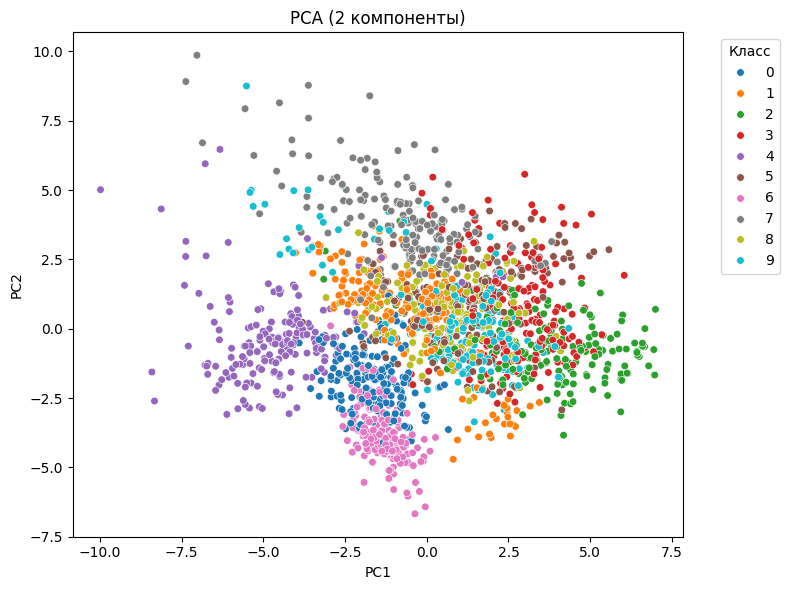

In [33]:
pca = PCA(n_components=2, random_state=42)
X_pca_digits = pca.fit_transform(X_scaled_digits)

print("Доля объяснённой дисперсии:", pca.explained_variance_ratio_,
      "Суммарно:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca_digits[:, 0], y=X_pca_digits[:, 1], hue=y_digits, palette="tab10", s=30)
plt.title("PCA (2 компоненты)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

Доля объяснённой дисперсии: [0.20163866 0.16144284] Суммарно: 0.3630815019516984


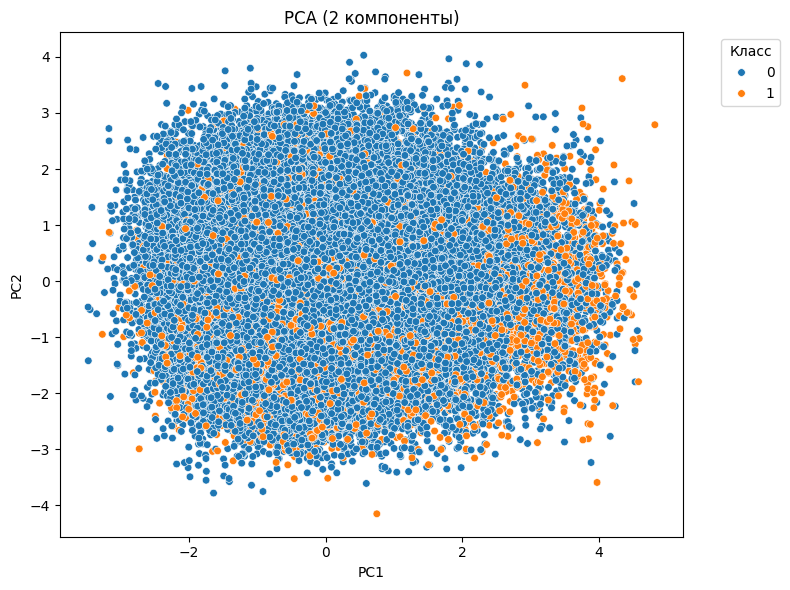

In [34]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Доля объяснённой дисперсии:", pca.explained_variance_ratio_,
      "Суммарно:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette="tab10", s=30)
plt.title("PCA (2 компоненты)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

TSNE 2 компоненты

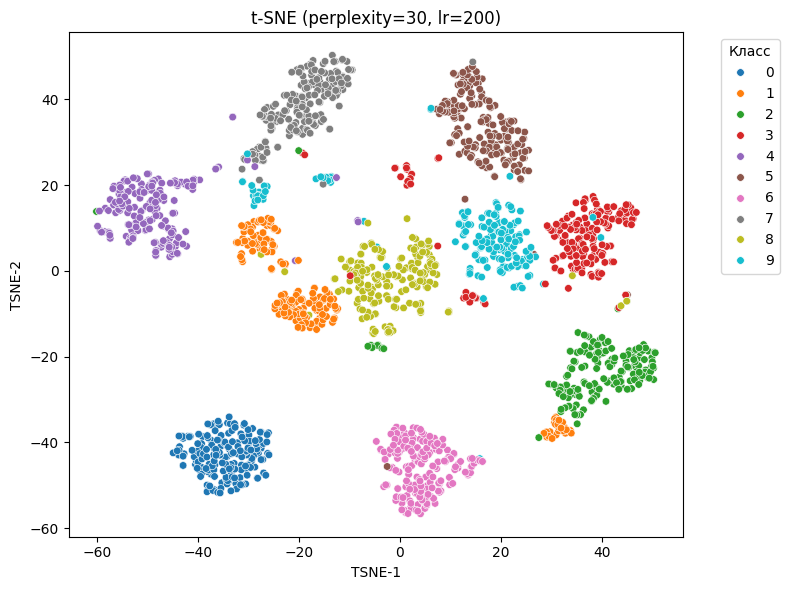

In [35]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    learning_rate=200
)

X_tsne_digits = tsne.fit_transform(X_scaled_digits)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne_digits[:, 0], y=X_tsne_digits[:, 1], hue=y_digits, palette="tab10", s=30)
plt.title("t-SNE (perplexity=30, lr=200)")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

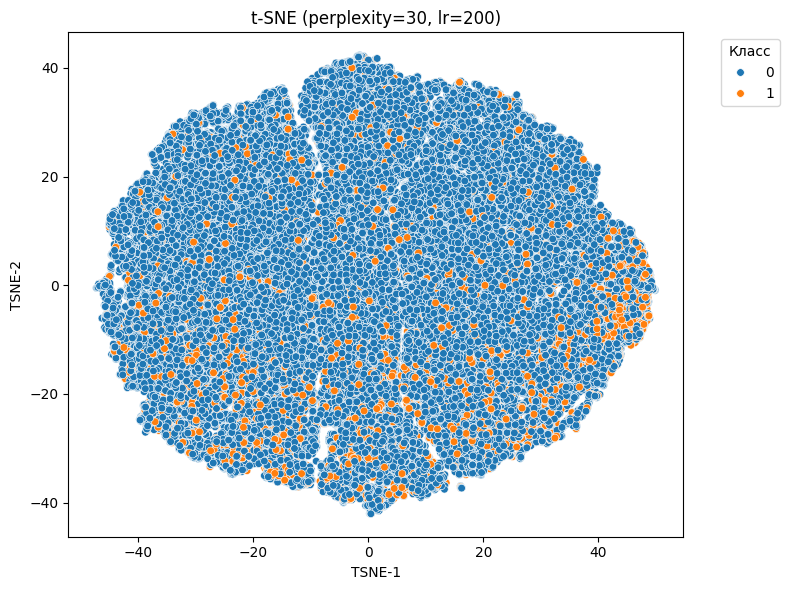

In [36]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    learning_rate=200
)

X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y, palette="tab10", s=30)
plt.title("t-SNE (perplexity=30, lr=200)")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [44]:
from sklearn.metrics import pairwise_distances

def separation_score(X_2d, y):
    D = pairwise_distances(X_2d)
    same = D[y[:, None] == y[None, :]]
    diff = D[y[:, None] != y[None, :]]
    return same.mean(), diff.mean(), diff.mean() / same.mean()

pca_same_digits, pca_diff_digits, pca_ratio_digits = separation_score(X_pca_digits, y_digits)
tsne_same_digits, tsne_diff_digits, tsne_ratio_digits = separation_score(X_tsne_digits, y_digits)

print("PCA:  среднее расстояние внутри класса =", pca_same_digits,
      ", между классами =", pca_diff_digits,
      ", ratio =", pca_ratio_digits)
print("t-SNE: среднее расстояние внутри класса =", tsne_same_digits,
      ", между классами =", tsne_diff_digits,
      ", ratio =", tsne_ratio_digits)

PCA:  среднее расстояние внутри класса = 2.4682343991638227 , между классами = 4.7614561566878075 , ratio = 1.9290939945982732
t-SNE: среднее расстояние внутри класса = 13.999029 , между классами = 55.66477 , ratio = 3.9763305


In [57]:
X_pca_10k = X_pca[:10000]
X_tsne_10k = X_tsne[:10000]
y_10k = y[:10000].to_numpy()

pca_same, pca_diff, pca_ratio = separation_score(X_pca_10k, y_10k)
tsne_same, tsne_diff, tsne_ratio = separation_score(X_tsne_10k, y_10k)

print("PCA:  среднее расстояние внутри класса =", pca_same,
      ", между классами =", pca_diff,
      ", ratio =", pca_ratio)
print("t-SNE: среднее расстояние внутри класса =", tsne_same,
      ", между классами =", tsne_diff,
      ", ratio =", tsne_ratio)

PCA:  среднее расстояние внутри класса = 1.975920737386757 , между классами = 2.142696120281024 , ratio = 1.0844038830802671
t-SNE: среднее расстояние внутри класса = 37.622936 , между классами = 39.62635 , ratio = 1.0532498


Вычислить и отрисовать T-SNE с разным значением Perplexity

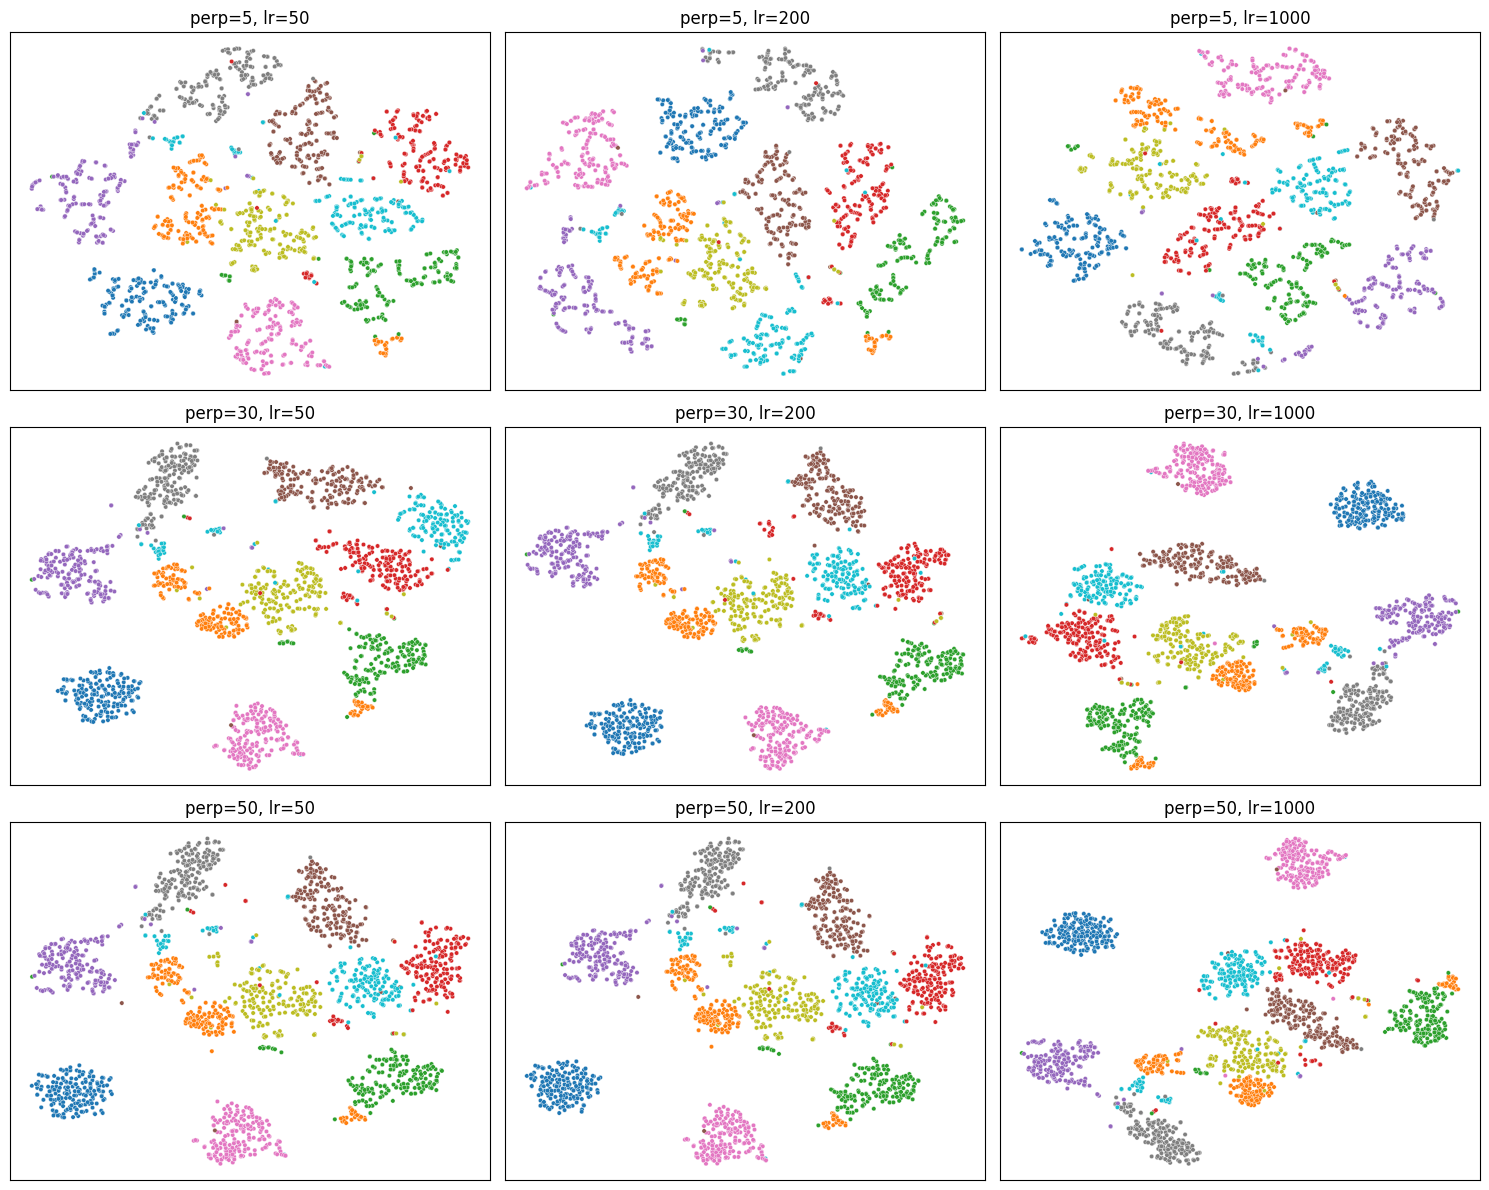

In [59]:
perplexities = [5, 30, 50]
learning_rates = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(learning_rates),
                         figsize=(5*len(learning_rates), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(learning_rates):
        tsne = TSNE(
            perplexity=perp,
            learning_rate=lr,
            random_state=42
        )
        X_emb_digits = tsne.fit_transform(X_scaled_digits)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb_digits[:, 0], y=X_emb_digits[:, 1],
                        hue=y_digits, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"perp={perp}, lr={lr}")
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

Завершён цикл 0-0
Завершён цикл 0-1
Завершён цикл 0-2
Завершён цикл 1-0
Завершён цикл 1-1
Завершён цикл 1-2
Завершён цикл 2-0
Завершён цикл 2-1
Завершён цикл 2-2


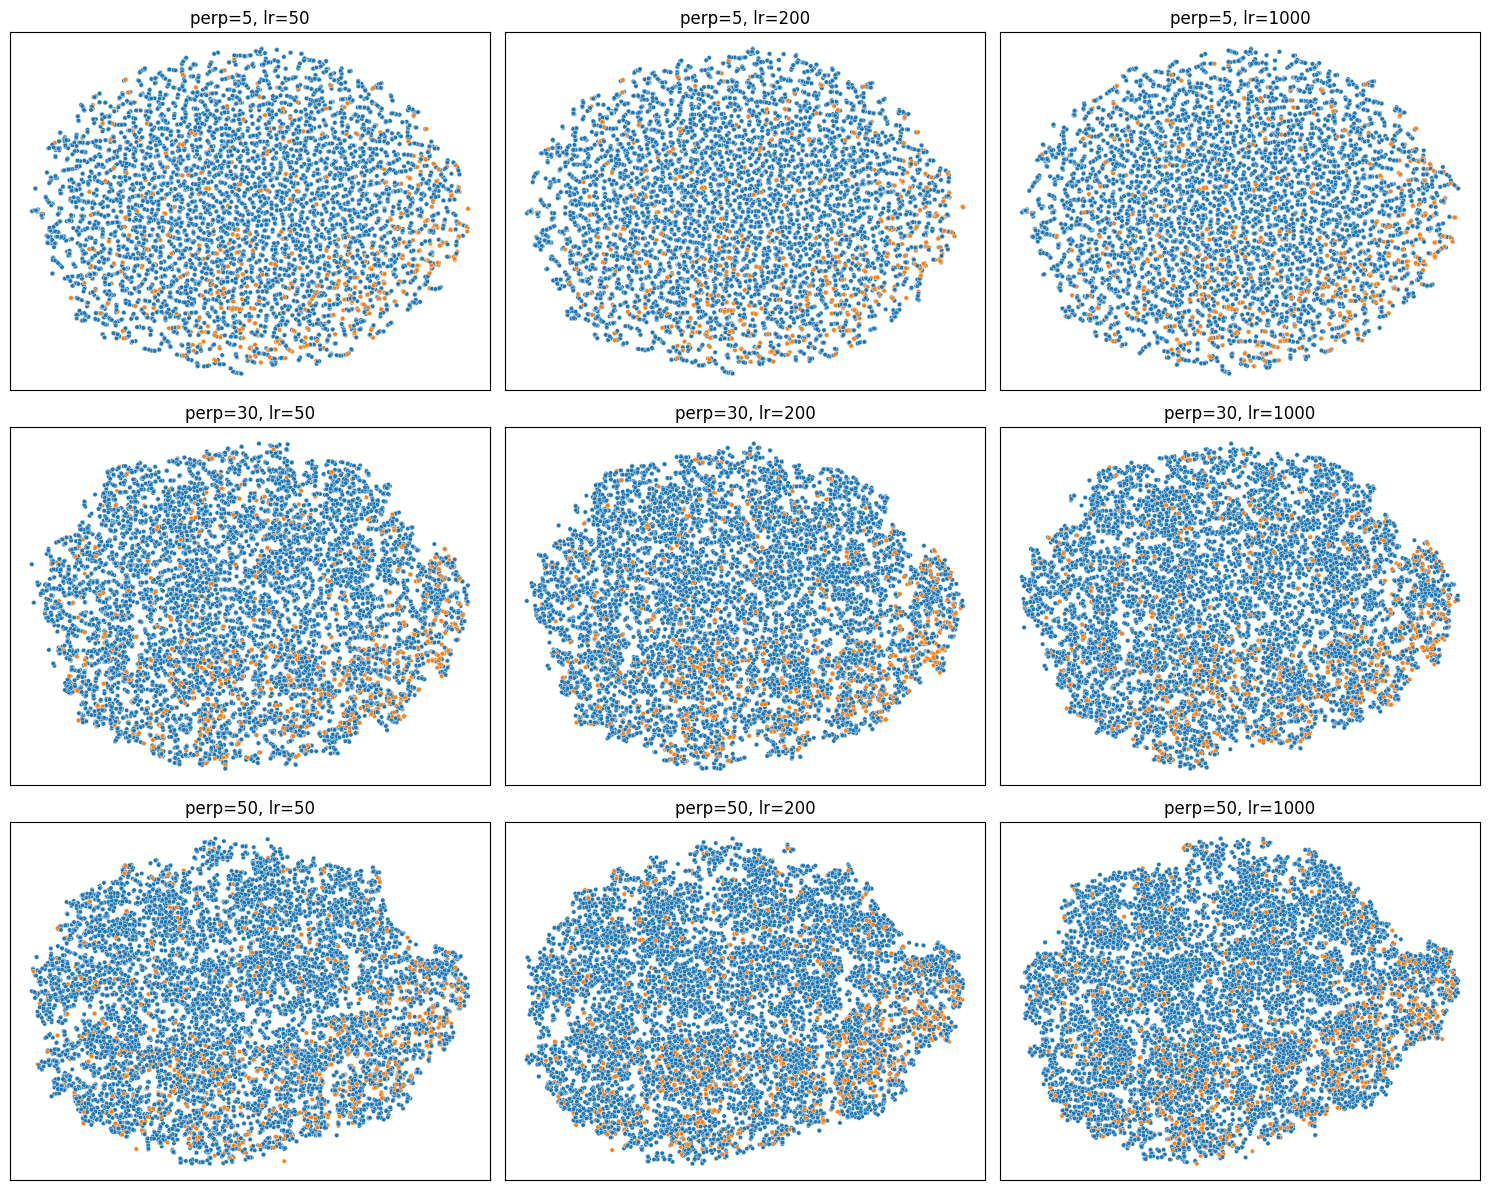

In [62]:
perplexities = [5, 30, 50]
learning_rates = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(learning_rates),
                         figsize=(5*len(learning_rates), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(learning_rates):
        tsne = TSNE(
            perplexity=perp,
            learning_rate=lr,
            random_state=42
        )
        X_emb_10k = tsne.fit_transform(X_scaled[:10000])
        ax = axes[i, j]
        sns.scatterplot(x=X_emb_10k[:, 0], y=X_emb_10k[:, 1],
                        hue=y[:10000], palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"perp={perp}, lr={lr}")
        ax.set_xticks([])
        ax.set_yticks([])
        print(f"Завершён цикл {i}-{j}")

plt.tight_layout()
plt.show()

- При меньших значения perplexity кластеры более разряжены, а learn rate влияет на расстояния между кластерами
- Небольшие изменения perplexity влияет средне на рисунок
- Небольшие изменения learn rate сильно влияет на рисунок

Проанализируйте:

как меняется форма кластеров,

возникают ли “разрывы” или слияния при разных параметрах,

насколько стабилен рисунок при небольших изменениях параметров.

PCA: устойчивая структура
Для PCA параметров немного (по сути только число компонент), проекция при фиксированном random_state практически не меняется, что показывает устойчивость метода.

Можно показать, что при разных n_components (2, 3, больше) первые две компоненты остаются близкими, а общая структура мало меняется.

In [63]:
n_components = [2, 3, 4, 5, 10]

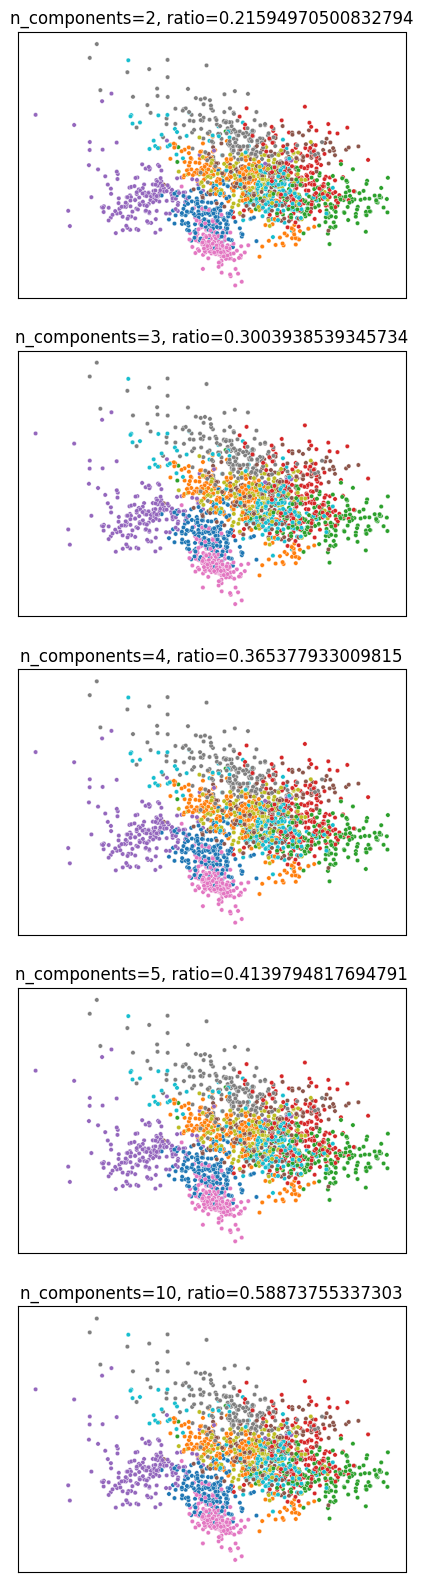

In [65]:
fig, axes = plt.subplots(len(n_components), 1, figsize=(len(n_components), 4*len(n_components)))

for i, n in enumerate(n_components):
  pca = PCA(n_components=n, random_state=42)
  X_pca = pca.fit_transform(X_scaled_digits)

  ax = axes[i]
  sns.scatterplot(x=X_pca_digits[:, 0], y=X_pca_digits[:, 1],
                hue=y_digits, palette="tab10", s=10, ax=ax, legend=False)
  ax.set_title(f"n_components={n}, ratio={pca.explained_variance_ratio_.sum()}")
  ax.set_xticks([])
  ax.set_yticks([])

In [66]:
n_components = [2, 3, 4, 5]

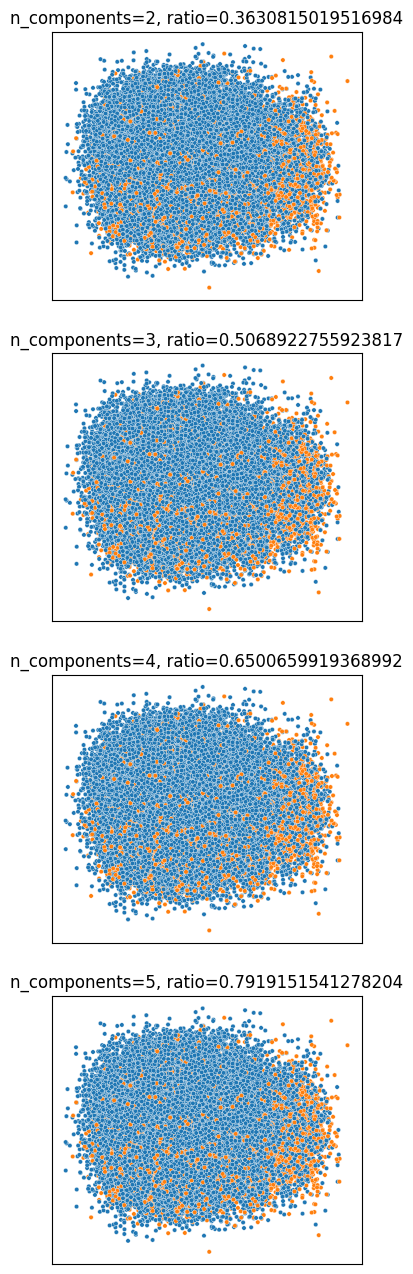

In [67]:
fig, axes = plt.subplots(len(n_components), 1, figsize=(len(n_components), 4*len(n_components)))

for i, n in enumerate(n_components):
  pca = PCA(n_components=n, random_state=42)
  X_pca = pca.fit_transform(X_scaled)

  ax = axes[i]
  sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1],
                hue=y, palette="tab10", s=10, ax=ax, legend=False)
  ax.set_title(f"n_components={n}, ratio={pca.explained_variance_ratio_.sum()}")
  ax.set_xticks([])
  ax.set_yticks([])